# Pemrosesan Data KBJI 2014 untuk IndoBERT w-SEAT

Notebook ini membaca bagian Profesional dari PDF KBJI 2014, mengaudit serta membersihkan artefak tanda petik secara konservatif, dan menyusun lexical set gender terdokumentasi. Tidak ada data sintetis atau hasil yang dipilih berdasarkan signifikansi.


## Konfigurasi dan data dictionary

occupation_name_raw hanya dipakai untuk audit. occupation_name adalah nama bersih yang mempertahankan tanda kurung, koma, slash, dan tanda hubung. cleaning_actions, changed, dan reason menjelaskan perubahan deterministik per baris.


In [1]:
import csv, math, platform, random, re, sys, time, unicodedata
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np, pandas as pd, pdfplumber, seaborn as sns
from IPython.display import Markdown, display
RANDOM_SEED=42; random.seed(RANDOM_SEED); np.random.seed(RANDOM_SEED)
ROOT=Path.cwd(); DATA_DIR=ROOT/"data"; TABLE_DIR=ROOT/"outputs"/"tables"; TABLE_DIR.mkdir(parents=True,exist_ok=True)
PDF_PATH=DATA_DIR/"KBJI 2014.pdf"; CLEAN_OUTPUT=DATA_DIR/"test1_v5_kbji_profesional_clean.csv"; LEXICON_OUTPUT=DATA_DIR/"test1_v5_gender_lexicon.csv"
AUDIT_OUTPUT=TABLE_DIR/"test1_v5_data_cleaning_audit.csv"; QUALITY_OUTPUT=TABLE_DIR/"test1_v5_data_quality_summary.csv"; LEXICON_AUDIT_OUTPUT=TABLE_DIR/"test1_v5_gender_lexicon_audit.csv"; PERMUTATION_OUTPUT=TABLE_DIR/"test1_v5_permutation_resolution.csv"
TIME_START=time.time(); TIME_START_ISO=time.strftime("%Y-%m-%dT%H:%M:%S%z"); assert PDF_PATH.exists()
print({"python":sys.version.split()[0],"platform":platform.platform(),"seed":RANDOM_SEED,"pdf_bytes":PDF_PATH.stat().st_size})


{'python': '3.14.0', 'platform': 'Windows-11-10.0.26200-SP0', 'seed': 42, 'pdf_bytes': 34550550}


## Lexical set gender yang terdokumentasi

core_identity ditetapkan sebagai pria-wanita dan laki-laki-perempuan. kinship, age_status, dan informal adalah sensitivitas karena membawa makna tambahan. existing_full mempertahankan delapan pasangan baseline fastText.


In [2]:
lexicon_rows=[
(1,"pria","wanita","core_identity","netral/formal","nomina identitas",False,False,False,False,True,True,"Steinhauer 2010; KBBI Daring","Caliskan et al. 2017; Antoniak dan Mimno 2021","Identitas umum; core utama."),
(2,"laki-laki","perempuan","core_identity","netral","nomina identitas",False,False,False,False,True,True,"Steinhauer 2010; KBBI Daring","Caliskan et al. 2017; Steinborn et al. 2022","Identitas umum; core sensitivitas."),
(3,"ayah","ibu","kinship","netral","nomina kekerabatan",False,True,False,False,False,True,"KBBI Daring","Antoniak dan Mimno 2021","Makna kekerabatan."),
(4,"suami","istri","kinship","netral","nomina relasional",False,True,True,False,False,True,"KBBI Daring","Antoniak dan Mimno 2021","Relasi dan status perkawinan."),
(5,"putra","putri","kinship","netral","nomina kekerabatan",False,True,False,False,False,True,"KBBI Daring","Antoniak dan Mimno 2021","Kekerabatan/generasi."),
(6,"pemuda","pemudi","age_status","netral","nomina usia/generasi",True,False,False,False,False,True,"KBBI Daring","Steinborn et al. 2022","Usia/generasi tambahan."),
(7,"jejaka","gadis","age_status","netral","nomina usia/status",True,False,False,False,False,True,"KBBI Daring","Steinborn et al. 2022","Usia/status tambahan."),
(8,"cowok","cewek","informal","informal","nomina identitas",False,False,False,True,False,True,"KBBI Daring","Antoniak dan Mimno 2021","Eksperimen register informal.")]
cols=["pair_id","male_term","female_term","lexical_category","register","grammatical_class","age_signal","kinship_signal","marital_status_signal","informality_signal","include_core","include_extended","source_lexicographic","source_academic","source_notes","inclusion_reason","exclusion_reason"]
gender_lexicon=pd.DataFrame([x+("ditetapkan a priori","") for x in lexicon_rows],columns=cols)
gender_lexicon["existing_full"]=True; gender_lexicon["pair_label"]=gender_lexicon["male_term"]+"–"+gender_lexicon["female_term"]
display(gender_lexicon)


,pair_id,male_term,female_term,lexical_category,register,grammatical_class,age_signal,kinship_signal,marital_status_signal,informality_signal,include_core,include_extended,source_lexicographic,source_academic,source_notes,inclusion_reason,exclusion_reason,existing_full,pair_label
0,1,pria,wanita,core_identity,netral/formal,nomina identitas,False,False,False,False,True,True,Steinhauer 2010; KBBI Daring,Caliskan et al. 2017; Antoniak dan Mimno 2021,Identitas umum; core utama.,ditetapkan a priori,,True,pria–wanita
1,2,laki-laki,perempuan,core_identity,netral,nomina identitas,False,False,False,False,True,True,Steinhauer 2010; KBBI Daring,Caliskan et al. 2017; Steinborn et al. 2022,Identitas umum; core sensitivitas.,ditetapkan a priori,,True,laki-laki–perempuan
2,3,ayah,ibu,kinship,netral,nomina kekerabatan,False,True,False,False,False,True,KBBI Daring,Antoniak dan Mimno 2021,Makna kekerabatan.,ditetapkan a priori,,True,ayah–ibu
3,4,suami,istri,kinship,netral,nomina relasional,False,True,True,False,False,True,KBBI Daring,Antoniak dan Mimno 2021,Relasi dan status perkawinan.,ditetapkan a priori,,True,suami–istri
4,5,putra,putri,kinship,netral,nomina kekerabatan,False,True,False,False,False,True,KBBI Daring,Antoniak dan Mimno 2021,Kekerabatan/generasi.,ditetapkan a priori,,True,putra–putri
5,6,pemuda,pemudi,age_status,netral,nomina usia/generasi,True,False,False,False,False,True,KBBI Daring,Steinborn et al. 2022,Usia/generasi tambahan.,ditetapkan a priori,,True,pemuda–pemudi
6,7,jejaka,gadis,age_status,netral,nomina usia/status,True,False,False,False,False,True,KBBI Daring,Steinborn et al. 2022,Usia/status tambahan.,ditetapkan a priori,,True,jejaka–gadis
7,8,cowok,cewek,informal,informal,nomina identitas,False,False,False,True,False,True,KBBI Daring,Antoniak dan Mimno 2021,Eksperimen register informal.,ditetapkan a priori,,True,cowok–cewek


## Ekstraksi bagian Profesional dari PDF

Marker dan pola kode hierarki digunakan untuk mempertahankan keterlacakan ke PDF. Tabel raw ditampilkan sebelum normalisasi.


In [3]:
def compact(value): return re.sub(r"\s+"," ",str(value)).strip()
with pdfplumber.open(PDF_PATH) as pdf: page_texts=[p.extract_text() or "" for p in pdf.pages]
start_page=next(i+1 for i,t in enumerate(page_texts) if re.search(r"(?m)^Golongan Pokok$\s*\n^2\s+PROFESIONAL\s*$",t,re.I))
stop_page=start_page+next(i for i,t in enumerate(page_texts[start_page:],start=1) if re.search(r"(?m)^Golongan Pokok 3\s*$",t,re.I))-1
p2,p3,p4,p6=(re.compile(x) for x in [r"^(\d{2})\s+(.+)$",r"^(\d{3})\s+(.+)$",r"^(\d{4})\s+(.+)$",r"^(\d{4}\.\d{2})\s+(.+)$"])
major_groups,groups,subgroups,occupations={}, {}, {}, []; marker=None
for page_number in range(start_page,stop_page+1):
    page_text=page_texts[page_number-1]
    for raw_line in page_text.splitlines():
        line=compact(raw_line)
        if line in {"Golongan","Subgolongan","Jabatan"}: marker=line; continue
        m=p6.match(line)
        if marker=="Jabatan" and m:
            occupation_code,name=m.groups(); printed=re.search(r"Halaman\s+(\d+)",page_text)
            occupations.append({"occupation_code":occupation_code,"occupation_name_raw":name,"source_page_pdf":page_number,"source_page_printed":printed.group(1) if printed else ""}); continue
        m=p4.match(line)
        if marker=="Subgolongan" and m: subgroups.setdefault(*m.groups()); continue
        m=p3.match(line)
        if marker=="Golongan" and m: groups.setdefault(*m.groups()); continue
        m=p2.match(line)
        if m and m.group(1) in {"21","22","23","24","25","26"}: major_groups.setdefault(*m.groups())
df_raw=pd.DataFrame(occupations)
print({"start_page_pdf":start_page,"last_page_in_scope":stop_page,"raw_rows":len(df_raw),"major_groups":len(major_groups),"groups":len(groups),"subgroups":len(subgroups)})
display(df_raw.head()); display(df_raw.sample(min(5,len(df_raw)),random_state=RANDOM_SEED))


{'start_page_pdf': 159, 'last_page_in_scope': 330, 'raw_rows': 501, 'major_groups': 6, 'groups': 27, 'subgroups': 92}


,occupation_code,occupation_name_raw,source_page_pdf,source_page_printed
0,2111.01,Ahli Fisika (Umum),161,121
1,2111.02,Ahli Fisika Nuklir,161,121
2,2111.03,Ahli Fisika Mekanika,161,121
3,2111.04,Ahli Fisika Panas,161,121
4,2111.05,Ahli Fisika Sinar,162,122


,occupation_code,occupation_name_raw,source_page_pdf,source_page_printed
362,2521.02,Analis Database,287,247
73,2142.04,Ahli Teknik Konstruksi Landasan Pesawat Udara.,185,145
375,2611.02,Jaksa,292,252
155,2166.06,Ilustrator,211,171
104,2146.99,"Ahli Teknik Pertambangan, Metalurgi dan YBDI L...",194,154


## Audit tanda petik sebelum pembersihan

Audit ini dilakukan pada nilai hasil ekstraksi PDF, bukan delimiter CSV. Contoh baris terdampak ditampilkan sebelum pembersihan.


In [4]:
quote_chars=['"', "\u201c", "\u201d", "\u201e", "\u201f"]; quote_labels=["straight_quote","left_double_quote","right_double_quote","low_double_quote","high_reversed_quote"]
quote_audit_before=pd.DataFrame({"quote_type":quote_labels,"character":quote_chars,"count":[df_raw["occupation_name_raw"].astype(str).str.contains(re.escape(ch),regex=True).sum() for ch in quote_chars]})
display(quote_audit_before)
for ch in quote_chars:
    ex=df_raw[df_raw["occupation_name_raw"].astype(str).str.contains(re.escape(ch),regex=True,na=False)][["occupation_code","occupation_name_raw"]].head()
    if len(ex): display(Markdown("Contoh "+repr(ch))); display(ex)


,quote_type,character,count
0,straight_quote,"""",0
1,left_double_quote,“,0
2,right_double_quote,”,0
3,low_double_quote,„,0
4,high_reversed_quote,‟,0


## Normalisasi konservatif dan audit perubahan

Unicode NFKC, quote literal, line break, carriage return, karakter nonprinting, whitespace berulang, dan spasi sebelum tanda baca ditangani. Tanda kurung, koma, slash, dan tanda hubung tidak dihapus otomatis.


In [5]:
def normalize_name(value):
    original="" if pd.isna(value) else str(value); text=unicodedata.normalize("NFKC",original); actions=[]
    if text!=original: actions.append("unicode_nfkc")
    if any(ch in text for ch in quote_chars): text=text.translate(str.maketrans({ch:"" for ch in quote_chars})); actions.append("hapus_tanda_petik_literal")
    if "\n" in text or "\r" in text: text=text.replace("\n"," ").replace("\r"," "); actions.append("hapus_line_break")
    clean="".join(ch for ch in text if unicodedata.category(ch) not in {"Cc","Cf"} or ch=="\t")
    if clean!=text: text=clean; actions.append("hapus_karakter_nonprinting")
    clean=re.sub(r"\s+"," ",text).strip()
    if clean!=text: text=clean; actions.append("collapse_whitespace")
    clean=re.sub(r"\s+([,.;:!?%\)\]])",r"\1",re.sub(r"([\(\[])\s+",r"\1",text))
    if clean!=text: text=clean; actions.append("perapian_spasi_tanda_baca")
    return text,"; ".join(actions) if actions else "tidak ada perubahan"
cleaned=df_raw["occupation_name_raw"].map(normalize_name); df_all=df_raw.copy(); df_all["occupation_name"]=cleaned.map(lambda x:x[0]); df_all["cleaning_actions"]=cleaned.map(lambda x:x[1])
df_all["changed"]=df_all["occupation_name_raw"].astype(str)!=df_all["occupation_name"]; df_all["reason"]=np.where(df_all["changed"],df_all["cleaning_actions"],"tidak ada artefak terdeteksi")
df_all["major_group_code"],df_all["major_group_name"]="2","Profesional"; df_all["submajor_group_code"]=df_all["occupation_code"].str[:2]; df_all["submajor_group_name"]=df_all["submajor_group_code"].map(major_groups)
df_all["group_code"]=df_all["occupation_code"].str[:3]; df_all["group_name"]=df_all["group_code"].map(groups); df_all["subgroup_code"]=df_all["occupation_code"].str[:4]; df_all["subgroup_name"]=df_all["subgroup_code"].map(subgroups)
df_all["source_document"]=PDF_PATH.name; df_all["preprocessing_version"]="test1_v5_kbji_data_preprocessing"; df_all["token_count"]=df_all["occupation_name"].str.split().str.len()
terms=set(gender_lexicon["male_term"])|set(gender_lexicon["female_term"]); df_all["is_valid_code"]=df_all["occupation_code"].str.fullmatch(r"\d{4}\.\d{2}")&df_all["submajor_group_code"].isin(set(major_groups))
df_all["is_duplicate_code"]=df_all["occupation_code"].duplicated(keep=False); df_all["is_residual"]=df_all["occupation_code"].str.endswith(".99")|df_all["occupation_name"].str.contains(r"lainnya|ybdi|ytdl",case=False,na=False); df_all["contains_gender_attribute"]=df_all["occupation_name"].str.lower().map(lambda x:bool(set(re.findall(r"[\w-]+",x))&terms))
df_all["hierarchy_complete"]=df_all[["submajor_group_name","group_name","subgroup_name"]].notna().all(axis=1); df_all["hierarchy_prefix_match"]=df_all["submajor_group_code"].isin(major_groups)&df_all["group_code"].isin(groups)&df_all["subgroup_code"].isin(subgroups)
df_all["code_name_conflict"]=df_all.groupby("occupation_code")["occupation_name"].transform("nunique").gt(1); df_all["duplicate_occupation_name"]=df_all["occupation_name"].duplicated(keep=False); df_all["name_nonempty"]=df_all["occupation_name"].ne("")
df_all["include_analysis"]=df_all["is_valid_code"]&~df_all["is_duplicate_code"]&~df_all["is_residual"]&~df_all["contains_gender_attribute"]&df_all["hierarchy_complete"]&df_all["hierarchy_prefix_match"]&~df_all["code_name_conflict"]&df_all["name_nonempty"]; df_analysis=df_all[df_all["include_analysis"]].copy()
cleaning_audit=df_all[["occupation_code","occupation_name_raw","occupation_name","cleaning_actions","changed","reason","source_page_pdf","source_page_printed"]]
display(df_all[["occupation_code","occupation_name_raw","occupation_name","cleaning_actions","changed"]].head(15)); display(df_all[df_all["changed"]][["occupation_code","occupation_name_raw","occupation_name","cleaning_actions"]].head(20))


,occupation_code,occupation_name_raw,occupation_name,cleaning_actions,changed
0,2111.01,Ahli Fisika (Umum),Ahli Fisika (Umum),tidak ada perubahan,False
1,2111.02,Ahli Fisika Nuklir,Ahli Fisika Nuklir,tidak ada perubahan,False
2,2111.03,Ahli Fisika Mekanika,Ahli Fisika Mekanika,tidak ada perubahan,False
3,2111.04,Ahli Fisika Panas,Ahli Fisika Panas,tidak ada perubahan,False
4,2111.05,Ahli Fisika Sinar,Ahli Fisika Sinar,tidak ada perubahan,False
5,2111.06,Ahli Fisika Suara,Ahli Fisika Suara,tidak ada perubahan,False
6,2111.07,Ahli Fisika Listrik Dan Magnit,Ahli Fisika Listrik Dan Magnit,tidak ada perubahan,False
7,2111.08,Ahli Fisika Elektronika,Ahli Fisika Elektronika,tidak ada perubahan,False
8,2111.09,Ahli Fisika Medis,Ahli Fisika Medis,tidak ada perubahan,False
9,2111.10,Ahli Astronomi,Ahli Astronomi,tidak ada perubahan,False


,occupation_code,occupation_name_raw,occupation_name,cleaning_actions


## Quality control data

QC mencakup jumlah baris, kode, kelompok 21–26, missing, duplikasi, quote tersisa, whitespace, karakter nonprinting, dan komposisi satu/multi kata. Checkpoint 415 tidak dipaksakan.


,metric,observed,interpretation
0,baris raw,501,checkpoint 501
1,baris analisis,415,checkpoint 415
2,kode unik,501,deskriptif
3,kelompok,"[21, 22, 23, 24, 25, 26]",21-26
4,missing nama,0,target 0
5,duplikasi kode,0,target 0
6,duplikasi nama,0,ditampilkan
7,quote tersisa,0,target 0
8,spasi berulang,0,target 0
9,nonprinting,0,target 0


,submajor_group_code,submajor_group_name,raw_count,analysis_count
0,21,Ahli ilmu pengetahuan dan teknik,161,138
1,22,Profesional kesehatan,89,74
2,23,Profesional pendidikan,52,42
3,24,Profesional bisnis dan administrasi,38,29
4,25,Profesional teknologi informasi dan komunikasi,34,26
5,26,"Profesional hukum, sosial dan budaya",127,106


,contoh_nama
submajor_group_code,
21,"[Ahli Fisika (Umum), Ahli Fisika Nuklir, Ahli ..."
22,"[Dokter Umum, Dokter Keluarga, Dokter Spesiali..."
23,"[Dosen Ilmu Fisika, Dosen Ilmu Teknik dan Arsi..."
24,"[Akuntan, Auditor, Pengawas Keuangan]"
25,"[Analis Bisnis (TI), Konsultan Sistem, Desaine..."
26,"[Pengacara, Jaksa, Penuntut Umum]"


,token_count
count,415.000000
mean,2.814458
std,1.324895
min,1.000000
25%,2.000000
50%,3.000000
75%,3.000000
max,8.000000


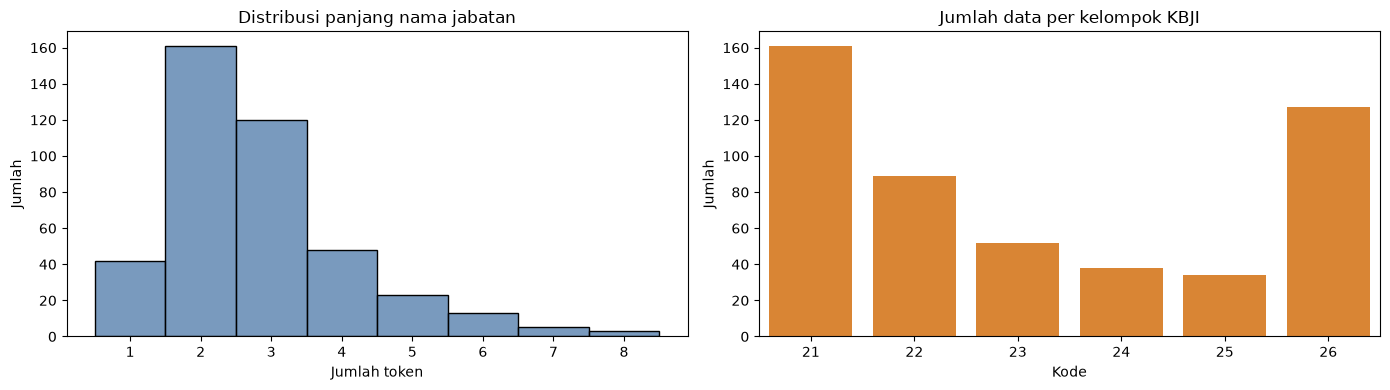

In [6]:
allowed_groups={"21","22","23","24","25","26"}; quote_remaining=int(df_all["occupation_name"].astype(str).apply(lambda x:any(ch in x for ch in quote_chars)).sum()); double_space_remaining=int(df_all["occupation_name"].astype(str).str.contains(r"\s{2,}").sum()); nonprinting_remaining=int(df_all["occupation_name"].astype(str).apply(lambda x:any(unicodedata.category(ch) in {"Cc","Cf"} and ch!="\t" for ch in x)).sum())
data_quality=pd.DataFrame([("baris raw",len(df_raw),"checkpoint 501"),("baris analisis",len(df_analysis),"checkpoint 415"),("kode unik",df_all["occupation_code"].nunique(),"deskriptif"),("kelompok",sorted(df_all["submajor_group_code"].dropna().unique()),"21-26"),("missing nama",int((~df_all["name_nonempty"]).sum()),"target 0"),("duplikasi kode",int(df_all["is_duplicate_code"].sum()),"target 0"),("duplikasi nama",int(df_all["duplicate_occupation_name"].sum()),"ditampilkan"),("quote tersisa",quote_remaining,"target 0"),("spasi berulang",double_space_remaining,"target 0"),("nonprinting",nonprinting_remaining,"target 0"),("satu kata",int((df_analysis["token_count"]==1).sum()),"deskriptif"),("multi-kata",int((df_analysis["token_count"]>1).sum()),"deskriptif")],columns=["metric","observed","interpretation"])
display(data_quality); display(df_all.groupby(["submajor_group_code","submajor_group_name"]).agg(raw_count=("occupation_code","size"),analysis_count=("include_analysis","sum")).reset_index()); display(df_analysis.groupby("submajor_group_code")["occupation_name"].apply(lambda x:x.head(3).tolist()).rename("contoh_nama").to_frame()); display(df_analysis[["occupation_name","token_count"]].describe())
fig,ax=plt.subplots(1,2,figsize=(14,4)); sns.histplot(data=df_analysis,x="token_count",discrete=True,ax=ax[0],color="#4C78A8"); ax[0].set(title="Distribusi panjang nama jabatan",xlabel="Jumlah token",ylabel="Jumlah"); counts=df_all.groupby("submajor_group_code").size().reset_index(name="count"); sns.barplot(data=counts,x="submajor_group_code",y="count",ax=ax[1],color="#F58518"); ax[1].set(title="Jumlah data per kelompok KBJI",xlabel="Kode",ylabel="Jumlah"); plt.tight_layout(); plt.show()


Nilai changed hanya mencatat aturan normalisasi. Proporsi multi-kata menjelaskan kebutuhan contextual phrase embedding, bukan dasar klaim gender.


## Audit lexical set dan resolusi permutation

Jumlah pembagian exact adalah C(2n,n). Core dengan dua pasangan memiliki enam pembagian dan resolusi p-value kasar; effect size, arah, dan stabilitas menjadi fokus core.


In [7]:
condition_pairs={"core_identity":gender_lexicon.loc[gender_lexicon["include_core"],"pair_id"].tolist(),"kinship":gender_lexicon.loc[gender_lexicon["lexical_category"].eq("kinship"),"pair_id"].tolist(),"age_status":gender_lexicon.loc[gender_lexicon["lexical_category"].eq("age_status"),"pair_id"].tolist(),"informal":gender_lexicon.loc[gender_lexicon["lexical_category"].eq("informal"),"pair_id"].tolist(),"existing_full":gender_lexicon["pair_id"].tolist()}
permutation_resolution=pd.DataFrame([{"lexical_condition":n,"n_male":len(p),"n_female":len(p),"exact_partition_count":math.comb(2*len(p),len(p)),"minimum_two_sided_resolution":1/math.comb(2*len(p),len(p)),"interpretation":"fokus effect size dan stabilitas" if n=="core_identity" else "istilah membawa makna tambahan"} for n,p in condition_pairs.items()])
gender_lexicon_audit=gender_lexicon[["pair_id","pair_label","lexical_category","register","grammatical_class","source_lexicographic","source_academic","source_notes","include_core","include_extended","existing_full"]]
display(gender_lexicon_audit); display(permutation_resolution)


,pair_id,pair_label,lexical_category,register,grammatical_class,source_lexicographic,source_academic,source_notes,include_core,include_extended,existing_full
0,1,pria–wanita,core_identity,netral/formal,nomina identitas,Steinhauer 2010; KBBI Daring,Caliskan et al. 2017; Antoniak dan Mimno 2021,Identitas umum; core utama.,True,True,True
1,2,laki-laki–perempuan,core_identity,netral,nomina identitas,Steinhauer 2010; KBBI Daring,Caliskan et al. 2017; Steinborn et al. 2022,Identitas umum; core sensitivitas.,True,True,True
2,3,ayah–ibu,kinship,netral,nomina kekerabatan,KBBI Daring,Antoniak dan Mimno 2021,Makna kekerabatan.,False,True,True
3,4,suami–istri,kinship,netral,nomina relasional,KBBI Daring,Antoniak dan Mimno 2021,Relasi dan status perkawinan.,False,True,True
4,5,putra–putri,kinship,netral,nomina kekerabatan,KBBI Daring,Antoniak dan Mimno 2021,Kekerabatan/generasi.,False,True,True
5,6,pemuda–pemudi,age_status,netral,nomina usia/generasi,KBBI Daring,Steinborn et al. 2022,Usia/generasi tambahan.,False,True,True
6,7,jejaka–gadis,age_status,netral,nomina usia/status,KBBI Daring,Steinborn et al. 2022,Usia/status tambahan.,False,True,True
7,8,cowok–cewek,informal,informal,nomina identitas,KBBI Daring,Antoniak dan Mimno 2021,Eksperimen register informal.,False,True,True


,lexical_condition,n_male,n_female,exact_partition_count,minimum_two_sided_resolution,interpretation
0,core_identity,2,2,6,0.166667,fokus effect size dan stabilitas
1,kinship,3,3,20,0.050000,istilah membawa makna tambahan
2,age_status,2,2,6,0.166667,istilah membawa makna tambahan
3,informal,1,1,2,0.500000,istilah membawa makna tambahan
4,existing_full,8,8,12870,0.000078,istilah membawa makna tambahan


## Menulis CSV final

CSV final berisi nama bersih dan metadata hierarki. Bentuk raw dan tindakan cleaning disimpan di audit terpisah. utf-8-sig dan QUOTE_MINIMAL menjaga serialisasi valid.


In [8]:
final_columns=["occupation_code","occupation_name","major_group_code","major_group_name","submajor_group_code","submajor_group_name","group_code","group_name","subgroup_code","subgroup_name","source_document","source_page_pdf","source_page_printed","preprocessing_version","token_count","is_valid_code","is_duplicate_code","is_residual","contains_gender_attribute","hierarchy_complete","hierarchy_prefix_match","code_name_conflict","duplicate_occupation_name","name_nonempty","include_analysis"]
df_all[final_columns].to_csv(CLEAN_OUTPUT,index=False,encoding="utf-8-sig",quoting=csv.QUOTE_MINIMAL); gender_lexicon.to_csv(LEXICON_OUTPUT,index=False,encoding="utf-8-sig",quoting=csv.QUOTE_MINIMAL); cleaning_audit.to_csv(AUDIT_OUTPUT,index=False,encoding="utf-8-sig",quoting=csv.QUOTE_MINIMAL); data_quality.to_csv(QUALITY_OUTPUT,index=False,encoding="utf-8-sig",quoting=csv.QUOTE_MINIMAL); gender_lexicon_audit.to_csv(LEXICON_AUDIT_OUTPUT,index=False,encoding="utf-8-sig",quoting=csv.QUOTE_MINIMAL); permutation_resolution.to_csv(PERMUTATION_OUTPUT,index=False,encoding="utf-8-sig",quoting=csv.QUOTE_MINIMAL)
readback=pd.read_csv(CLEAN_OUTPUT,dtype={"occupation_code":str,"major_group_code":str,"submajor_group_code":str,"group_code":str,"subgroup_code":str,"source_page_printed":str})
print({"clean_rows":len(readback),"analysis_rows":int(readback["include_analysis"].sum()),"changed_rows":int(cleaning_audit["changed"].sum()),"duration_seconds":round(time.time()-TIME_START,2)})
assert len(readback)==len(df_all) and set(readback.loc[readback["include_analysis"],"submajor_group_code"])==allowed_groups and readback["occupation_name"].notna().all() and not readback["occupation_name"].str.contains(r"\s{2,}").any()


{'clean_rows': 501, 'analysis_rows': 415, 'changed_rows': 0, 'duration_seconds': 97.39}


## Referensi dan verifikasi akhir

Steinhauer (2010), KBBI Daring, Antoniak dan Mimno (2021), Steinborn et al. (2022), dan Caliskan et al. (2017) menjadi dasar dokumentasi lexical/WEAT. Wilie et al. (2020) menjadi rujukan IndoNLU/IndoBERT.


In [9]:
final_data_qc=pd.DataFrame([{"check":"CSV final tersedia","status":CLEAN_OUTPUT.exists()},{"check":"lexical CSV tersedia","status":LEXICON_OUTPUT.exists()},{"check":"audit tersedia","status":AUDIT_OUTPUT.exists()},{"check":"kelompok 21-26","status":set(df_analysis["submajor_group_code"])==allowed_groups},{"check":"quote literal tersisa 0","status":quote_remaining==0},{"check":"nama tidak kosong","status":bool(df_all["name_nonempty"].all())},{"check":"readback jumlah sama","status":len(readback)==len(df_all)}])
display(final_data_qc); assert final_data_qc["status"].all()


,check,status
0,CSV final tersedia,True
1,lexical CSV tersedia,True
2,audit tersedia,True
3,kelompok 21-26,True
4,quote literal tersisa 0,True
5,nama tidak kosong,True
6,readback jumlah sama,True
